# Introduction to Machine Learning -- MC886
# Assignment 2 - Model Selection and Regularization

**Professor:** Marcelo da Silva Reis  
**PED:** Heigon Soldera

In [1]:
# Please, enter your name and RA number in the lines below:
print(f"{"Álvaro Brandão de Carvalho":32}", "|", "195033")
print(f"{"Henrique Cazarim Meirelles Alves":32}", "|", "24763")

Álvaro Brandão de Carvalho       | 195033
Henrique Cazarim Meirelles Alves | 24763


---

## Objective

This assignment investigates the effects of overfitting in different data regimes
and test conditions.
The goal is to understand the different results of regularization when data
availability changes, and how they impact the generalization across **three**
different distributions: the one used for training, the clean one, and a
corruption the model has never seen.

### Guidelines

> Please read these guidelines carefully.

1. Questions can be answered in English or in Portuguese.

2. Use data visualization as a primary tool for understanding the problem. Inspect the training data, corrupted inputs, and model behavior. When an assumption is uncertain, verify it empirically through plots.

3. The provided code serves only as a reference. Modifications are allowed, including changes to functions and the introduction of new components. Code clarity and organization are required.

4. The use of generative AI tools (e.g., ChatGPT, GitHub Copilot, DeepSeek, LLaMA) is permitted strictly for implementation support. The use of AI for interpreting, analyzing, or discussing experimental results is discouraged. Submissions must include:
	- A declaration of which models were used.
	- The prompts that generated any incorporated code.

5. Do not hesitate to reach out to the PED/PAD via Discord.

### About the Dataset

This assignment uses the [MNIST](https://web.archive.org/web/20240213122836/http://yann.lecun.com/exdb/mnist/) dataset, a standard benchmark for image classification. It consists of 28×28 grayscale images of handwritten digits (0–9), where each pixel encodes an intensity value in [0, 255].

MNIST is useful here because it is simple enough that a linear model can do well on it, which means the learned weights are directly interpretable as images, where each weight corresponds to the influence of each pixel.

To study robustness and distribution shift, the images were corrupted with one of the corruptions of [MNIST-C](https://github.com/google-research/mnist-c) (Mu & Gilmer, 2019). Which corruption it is, is for you to find out in Part 1.

The training set consists entirely of corrupted images. The test set contains **three splits** of the same 10,000 test images:
- `test_corrupted`: corrupted test images (same corruption as training).
- `test_clean`: the original, uncorrupted MNIST test images.
- `test_impulse`: the test images with a **different** corruption, impulse (salt-and-pepper) noise, never seen during training.

Performance on `test_corrupted` measures how well the model learned the training task.
Performance on `test_clean` measures how well the model learned digit recognition.
Performance on `test_impulse` measures whether the robustness acquired during training transfers to a corruption the model was never exposed to.

Your job is to train three different models, each one with different number of
available samples:
- Full-data (60000 samples)
- Partial-data (10000 samples)
- Scarce-data (1000 samples)

Finding the best combination of hyper-parameter for each one of them.

In [2]:
from typing import Any

from numpy.typing import NDArray
import numpy as np
import pandas as pd
import random

import torch
import torch.nn as nn
from torch import optim

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

# Set random seeds for reproducibility.
# Do not tune this number
# Re-run the notebook from the beginning before submitting.
seed = 42
torch.random.manual_seed(seed)
np.random.seed(seed)
random.seed(seed)

In [3]:
# The dataset is available in the classroom assignment.
# Ensure you have downloaded it and placed it alongside this notebook.

# DO NOT change this cell

def subsample_dataset(
	X: NDArray[Any], y: NDArray[Any], n: int
) -> tuple[NDArray[Any], NDArray[Any]]:
	n_samples = len(y)

	idxs = np.random.choice(
		n_samples, size=n, replace=False
	)

	return X[idxs], y[idxs]

DATA_DIR = "data_2s2026"

X_full = np.load(f"{DATA_DIR}/train/train_images.npy")
y_full = np.load(f"{DATA_DIR}/train/train_labels.npy")

X_partial, y_partial = subsample_dataset(X_full, y_full, 10_000)
X_scarce, y_scarce = subsample_dataset(X_full, y_full, 1_000)

print(f"Full-data set: {X_full.shape[0]} samples")
print(f"Partial-data set: {X_partial.shape[0]} samples")
print(f"Scarce-data set: {X_scarce.shape[0]} samples")

Full-data set: 60000 samples
Partial-data set: 10000 samples
Scarce-data set: 1000 samples


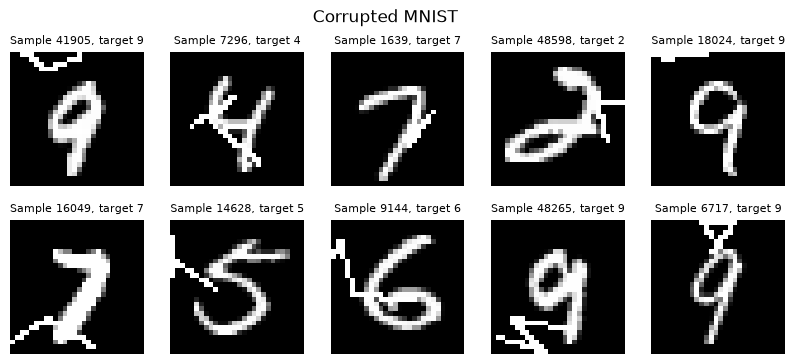

In [4]:
n_cols = 5
n_rows = 2

fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(2*n_cols, 2*n_rows))

fig.suptitle("Corrupted MNIST")

for i in range(n_rows):
	for j in range(n_cols):
		ax = axs[i, j]
		idx = random.randint(0, len(X_full)-1)

		ax.set_title(f"Sample {idx}, target {y_full[idx]}", fontsize=8)
		ax.imshow(X_full[idx], cmap='grey')
		ax.set_axis_off()

---

## Part 1. Data Analysis and Preprocessing

### 1.1 Exploring the corruption

**(1.0 point)**

Before any modeling, understand what the corruption actually does to the data.

Is the corruption random per-pixel noise, or is it a structured perturbation?
Explore the **training** dataset, understand the distribution and the effects of the introduced
noise. Useful tools are per-class mean images, per-pixel statistics (e.g., how often each
pixel is saturated at 255), and looking at many individual samples side by side.

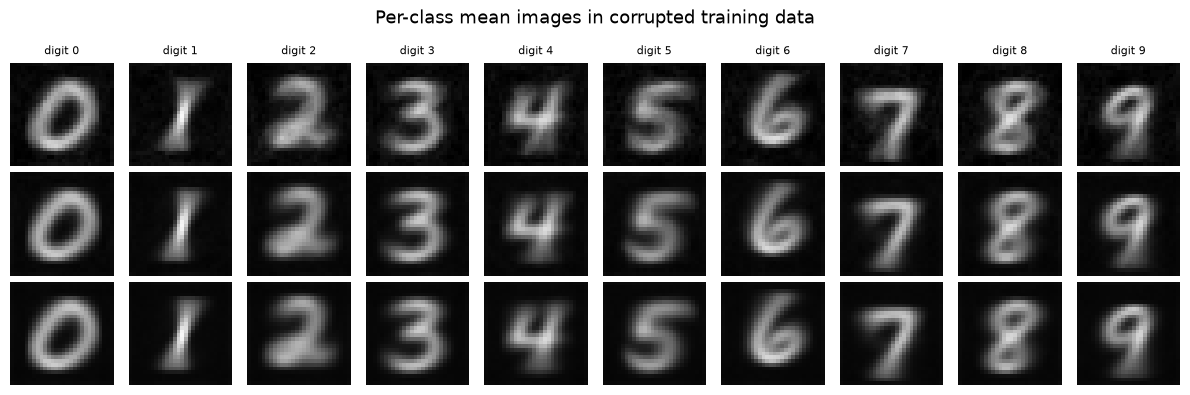

In [5]:
data_regimes = {
	"Scarce": (X_scarce, y_scarce),
	"Partial": (X_partial, y_partial),
	"Full": (X_full, y_full),
}

fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))
for digit in range(10):
	axs[0, digit].set_title(f"digit {digit}", fontsize=8)

for i, name in enumerate(data_regimes):
	X, y = data_regimes[name]


	for digit in range(10):
		mask = (y == digit)
		mean_img = X[mask].mean(axis=0)
		axs[i, digit].imshow(mean_img, cmap="gray", vmin=0, vmax=255)
		axs[i, digit].axis("off")

	axs[i, 0].set_ylabel(f"{name}-data regime", fontsize=9)

plt.suptitle("Per-class mean images in corrupted training data", fontsize=13)
plt.tight_layout()
plt.show()

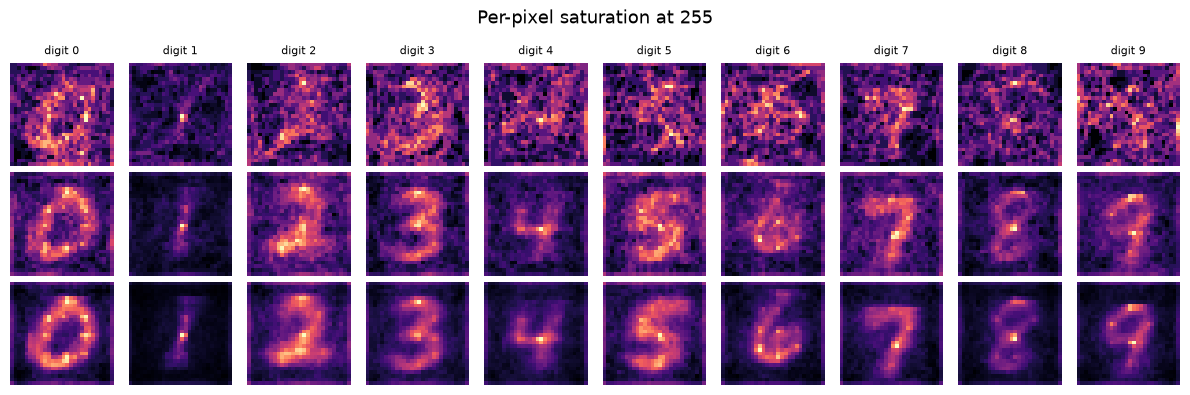

In [6]:
fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))
for digit in range(10):
	axs[0, digit].set_title(f"digit {digit}", fontsize=8)

for i, name in enumerate(data_regimes):
	X, y = data_regimes[name]


	for digit in range(10):
		mask = (y == digit)
		freq_img = (X[mask] == 255).mean(axis=0)
		axs[i, digit].imshow(freq_img, cmap="magma")
		axs[i, digit].axis("off")

	axs[i, 0].set_ylabel(f"{name}-data regime", fontsize=9)

plt.suptitle("Per-pixel saturation at 255", fontsize=13)
plt.tight_layout()
plt.show()

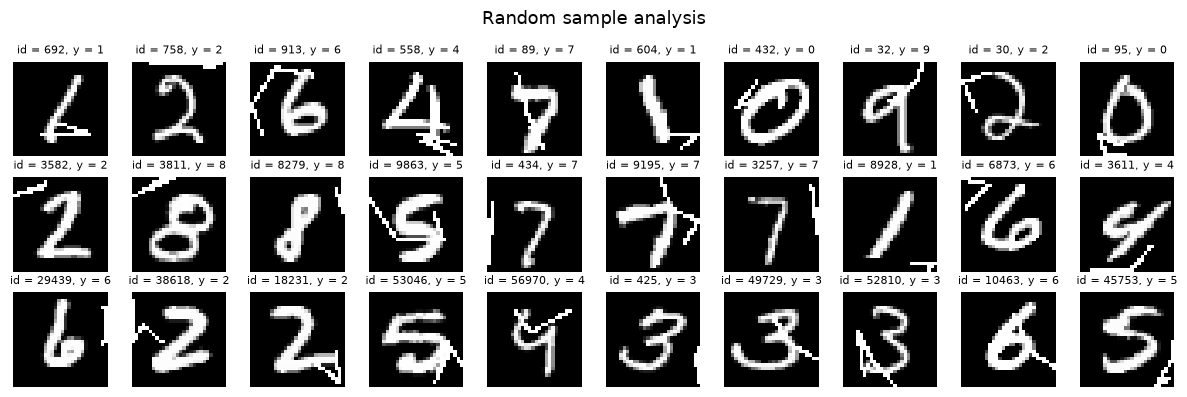

In [7]:
fig, axs = plt.subplots(len(data_regimes), 10, figsize=(4*len(data_regimes), 4))

for i, name in enumerate(data_regimes):
	X, y = data_regimes[name]

	for j in range(10):
		ax = axs[i, j]
		idx = random.randint(0, len(X)-1)

		ax.set_title(f"id = {idx}, y = {y[idx]}", fontsize=8)
		ax.imshow(X[idx], cmap='grey')
		ax.set_axis_off()

plt.suptitle("Random sample analysis", fontsize=13)
plt.tight_layout()
plt.show()

> **Question 1.1**
>
> (a) Describe the corruption. Is it random and per-sample, or is it systematic and shared across images? Does it vary across digit classes?
>
> (b) Why does the corruption turn into a faint, nearly uniform background in the per-class mean images? What does that tell you about using mean images to diagnose a corruption?
>
> (c) The corruption is made of strokes, and digits are also made of strokes. Which digits do you expect to be most easily confused with (or by) the corruption?
>
> (d) Are there data regimes where the corruption can affect the model more than in others?
> Hypothesize how these different regimes will affect a model trained on them.

**Answers:**

(a) The corruption consists of random, stroke-like white lines per-sample (not shared across samples and classes). It doesn't follow a systematic pattern across the dataset independently of the digit classes, showing high variance even within the same class. The visualization `Per-pixel saturation at 255` (Scarce, Partial and Full, respectively) confirms this independent noise hypotesis. We can easily notice in the Scarce data regime, cause with less data, the corruption has more weight in the mean image.

(b) Because the noise lines are random, uniformly distributed in coordinates, the average noise is insignificant when compared with the mean of the digit itself, which consistently appears in similar positions across most samples. This creates a faint in the mean image, demonstrating that mean images are ineffective for diagnosing high-variance and ramdonly localized spatial noise.

(c) We expect digits composed by simple and straight lines, such as 1, 7 or 4, are more susceptible. Because a simple stroke can be confused with a number 1, or transform a number 1 into 7, for example.

(d) We can suppose that the corruption heavily degrades the models trained with less information (Scarce, in this case). Because the model overfit random noise, falsely attributing these noise to a specific class. While models trained with more data has enough examples to recognize the noise is uncorrelated with the classes.

### 1.2 Preprocessing

**(1.0 point)**

Before training, the raw data must be brought into a form suitable for gradient-based optimization.

Two considerations are important here:

1. **Scale.** Raw pixel values are in [0, 255]. Gradient descent is sensitive to the scale of inputs; large input values produce large gradients, which can destabilize training.

2. **Data leakage.** Any statistics used for preprocessing must be computed from the training set only, then applied to all other splits.
Computing statistics on the full dataset, including test data, leaks information about the test distribution into preprocessing and invalidates evaluation.

In [8]:
scaled_data_regimes = {}

for regime in data_regimes:
	X, y = data_regimes[regime]
	X = X.reshape(len(X), -1).astype(np.float32)

	scaler = StandardScaler()
	X_scaled = scaler.fit_transform(X)
	scaled_data_regimes[regime] = (X_scaled, y, scaler)

> **Question 1.2**
>
> Describe the preprocessing choices made above. What strategy have you chosen, and why?

**Answer:** The preprocessing strategy addresses both the scale and data leakage. We used StandardScaler from scikit-learn with a flattened X ([samples, 28, 28, 1] &rarr; [samples, 784]), this operation standardize each pixel following: 
$$\hat{x}_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$
Where $\mu_j$ and $\sigma_j$ are the mean and standard deviation of pixel j, computed using only training data to avoid data leakage. This standardize process produces features with approximately zero mean and one unit of variance, which improves the numerical stability.

As said before, this scaler uses only training data to avoid data leakage. This same fitted scaler is then reused to transform the test set.
When using cross-validation methods, we will need to create a scaler for each fold used. In other words, the validation set is treated like the test set and the training set is standardized without the validation, after the fitting we transform the validation set to complete the cross-validation method.

---

## Part 2. Multinomial Logistic Regression

### 2.1 The model

Multinomial logistic regression (also called softmax regression) is the natural extension of binary logistic regression to $K > 2$ classes.

Given an input $\mathbf{x} \in \mathbb{R}^d$, the model computes a score (logit) for each class $k$:

$$z_k = \mathbf{w}_k^\top \mathbf{x} + b_k$$

Each logit is an unconstrained real number, in order to transform these values into
probabilities, where $p_k \geq 0$ and $\sum_k p_k = 1$, the softmax function
is used:

$$P(y = k \mid \mathbf{x}) = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$

Training minimizes the **cross-entropy loss**, which is the negative log-likelihood of the true class under this distribution:

$$\mathcal{L}(\mathbf{W}, \mathbf{b}) = -\frac{1}{N} \sum_{i=1}^{N} \log P(y_i \mid \mathbf{x}_i)$$

For MNIST with $d = 784$ pixels and $K = 10$ classes, the weight matrix $\mathbf{W} \in \mathbb{R}^{10 \times 784}$ has one row per class. Each row $\mathbf{w}_k$ can be reshaped into a 28×28 image and visualized directly: positive values indicate pixels whose brightness increases the log-odds of class $k$, whereas negative values suppress it.
This direct interpretability is one reason we use a linear model here.

### 2.2 Regularization

Standard cross-entropy minimization has no preference over the parameter space.
With enough capacity, or with corrupted data that contains spurious features, the model can assign large weights to uninformative or noisy pixels if doing so reduces training loss.

Regularization considers an additional assumption over the nature of the learned weights,
adding a penalty on the weights to the loss:

$$\mathcal{L}_{\text{reg}} = \mathcal{L} + \lambda \cdot \Omega(\mathbf{W})$$

Two common choices for $\Omega$:

- **L2 (Ridge):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_2^2 = \sum_{k,j} w_{kj}^2$. Penalizes large weights uniformly, where all weights shrink toward zero but none are forced exactly to zero.
In PyTorch's optimizers, L2 is implemented as `weight_decay`.

- **L1 (Lasso):** $\Omega(\mathbf{W}) = \|\mathbf{W}\|_1 = \sum_{k,j} |w_{kj}|$. Penalizes the sum of absolute values, producing sparse solutions where many weights are driven to exactly zero.

The hyperparameter $\lambda \geq 0$ controls the strength of regularization.
$\lambda = 0$ recovers the unregularized problem.

**(2.0 point)**

Implement the Multinomial Logistic Regression model using PyTorch's nn.Module
for the linear model (image as input and logits as outputs), and SGD with both
L1 and L2 regularization methods.

In [9]:
class LinearModel(nn.Module):
	def __init__(self, input_dim: int = 784, output_dim: int = 10):
		super(LinearModel, self).__init__()
		self.linear = nn.Linear(input_dim, output_dim)

	def forward(self, X: torch.Tensor) -> torch.Tensor:
		return self.linear(X)


def accuracy(logits: torch.Tensor, y: torch.Tensor) -> float:
	"""Fraction of correctly predicted samples."""
	y_pred = logits.argmax(dim=-1)
	return (y == y_pred).float().mean().item()


def train(
	model: nn.Module,
	X: torch.Tensor,
	y: torch.Tensor,
	n_iter: int,
	lr: float = 0.1,
	l1: float = 0.0,
	l2: float = 0.0
) -> list[float]:
	"""
	Train a model using full-batch SGD with L1/L2 regularization.

	Returns the list of per-iteration training losses.
	"""

	def lasso_reg(model: nn.Module, reg: float):
		weights = model.linear.weight
		return reg * weights.abs().sum()

	def ridge_reg(model: nn.Module, reg: float):
			weights = model.linear.weight
			return reg * (weights ** 2).sum()

	optimzer = optim.SGD(model.parameters(), lr=lr)

	loss_history = []
	cross_entropy = nn.CrossEntropyLoss()

	for _ in range(n_iter):
		optimzer.zero_grad()
		
		logits = model(X)
		
		loss = cross_entropy(logits, y)
		reg_loss = loss + lasso_reg(model, l1) + ridge_reg(model, l2)
		reg_loss.backward()

		optimzer.step()

		loss_history.append(reg_loss.item())

	return loss_history

### 2.3 Baseline mode

**(2.0 points)**

Train a unregularized model on each training set and observe the training loss
per iteration on each model during training.

To diagnose and understand what the trained model have learned, we visualize the
learned weights as a heatmap.

In [10]:
# Visualize learned weight images, one per digit class.
# Use a diverging colormap: red = positive weight (pixel increases log-odds),
# blue = negative weight (pixel suppresses log-odds).

def plot_weights(weights: NDArray[np.float32], title: str) -> None:
	fig, axs = plt.subplots(2, 5, figsize=(12, 5))
	fig.suptitle(title, fontsize=13)

	for digit in range(10):
		ax = axs[digit // 5, digit % 5]
		ax.imshow(weights[digit].reshape(28, 28), cmap="icefire")
		ax.set_title(f"digit {digit}", fontsize=9)
		ax.axis("off")

	plt.tight_layout()
	plt.show()

In [11]:
unregularized_models = {}

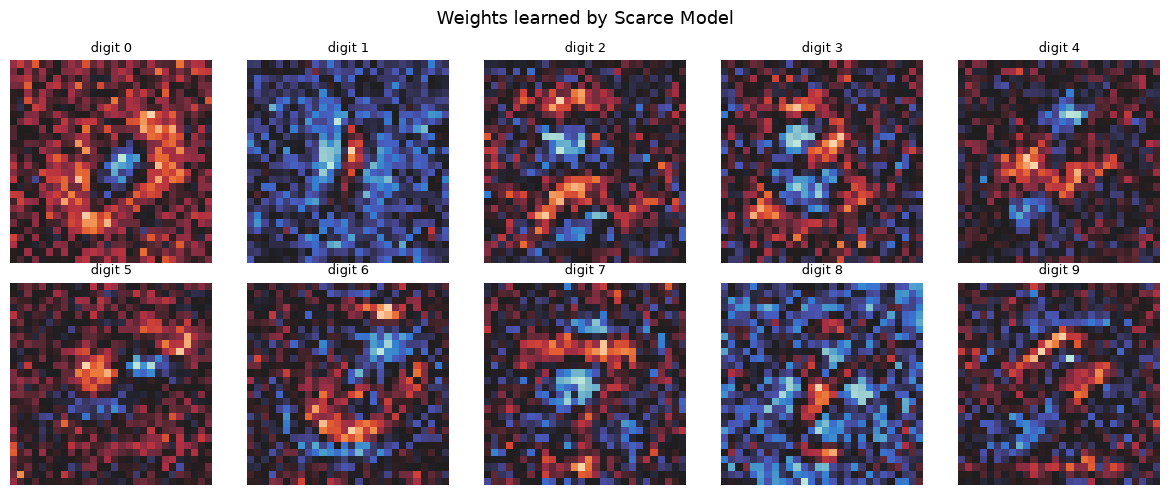

In [12]:
scarce_model = LinearModel()
X = torch.from_numpy(scaled_data_regimes['Scarce'][0]).float()
y = torch.from_numpy(scaled_data_regimes['Scarce'][1])

scarce_loss = train(scarce_model, X, y, n_iter=100)

unregularized_models['Scarce'] = (scarce_model, scarce_loss)

scarce_weights = scarce_model.linear.weight.detach().numpy()

plot_weights(scarce_weights, "Weights learned by Scarce Model")

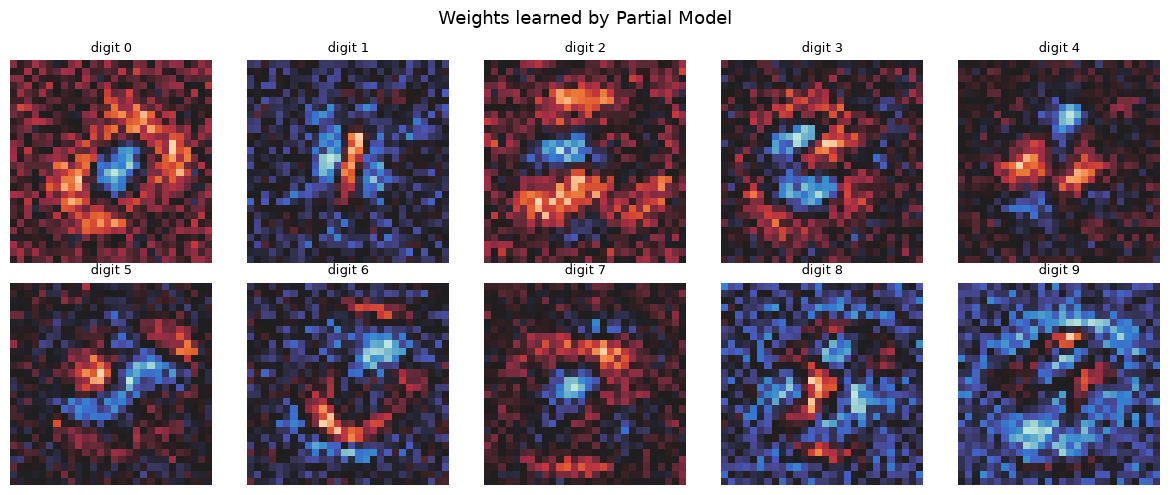

In [13]:
partial_model = LinearModel()
X = torch.from_numpy(scaled_data_regimes['Partial'][0]).float()
y = torch.from_numpy(scaled_data_regimes['Partial'][1])

partial_loss = train(partial_model, X, y, n_iter=100)

unregularized_models['Partial'] = (partial_model, partial_loss)

partial_weights = partial_model.linear.weight.detach().numpy()

plot_weights(partial_weights, "Weights learned by Partial Model")

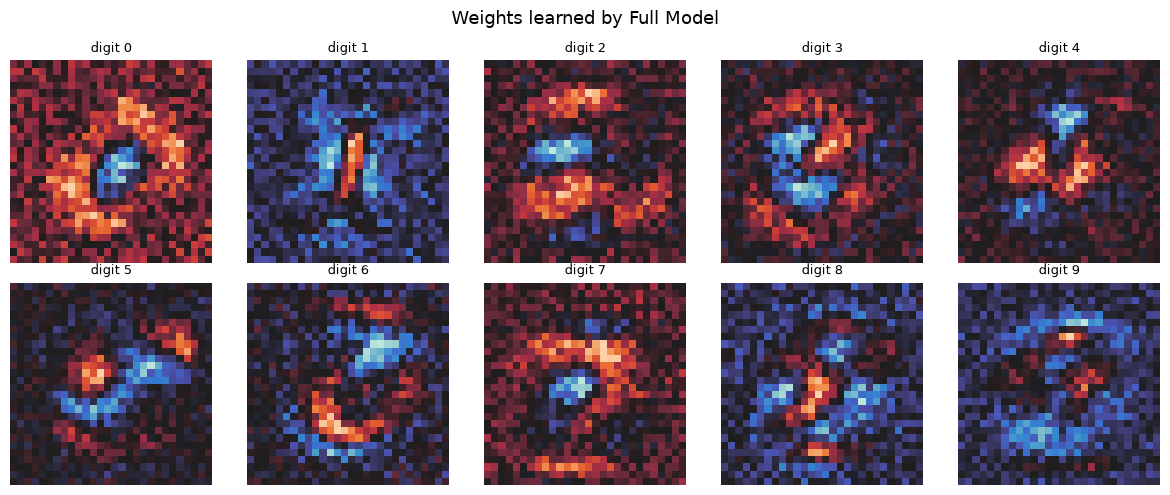

In [14]:
full_model = LinearModel()
X = torch.from_numpy(scaled_data_regimes['Full'][0]).float()
y = torch.from_numpy(scaled_data_regimes['Full'][1])

full_loss = train(full_model, X, y, n_iter=100)

unregularized_models['Full'] = (full_model, full_loss)

full_weights = full_model.linear.weight.detach().numpy()

plot_weights(full_weights, "Weights learned by Full Model")

> **Question 2.3**
>
> Inspect the weight images for each baseline model. How do you explain the
> weight values in the heatmap, and what patterns do they show?
>
> Compare between the model, how are they different?

**Answer:** Red pixels represent positive weights (increase log-odds for a specific class), while blue pixels represent negative weights (decrease log-odds for a specific class). Therefore we expect to see the silhouette of the target digit clearly outlined in red, rewarding the presence of pixels in those locations. The blue areas represent empty background and strokes from competing digits, allowing the model to differentiate shapes that belong to other classes.

The Scarce model displays a highly noisy background with weights scattered randomly outside the digit's core format. This is an indication that the model may be overfitting the limited data, learning to associate random noise strokes with specific classes. On the other hand, the Partial and Full models display significantly cleaner silhouettes and backgrounds, demonstrating that with sufficient data the model can successfully learn to ignore the random corruption. The visual difference between the Partial and Full plots is minimal, suggesting that 10k samples of Partial data regime are already sufficient for the model to ignore this specific random noise.

---

## Part 3. Regularization

**(2.0 points)**

We now introduce regularization and sweep over $\lambda$ values for both L1 and L2 penalties.

Your **only decision criterion** in this part is cross-validation accuracy computed on the corrupted training data, exactly what you would have in a real scenario without access to a clean or differently corrupted test set.

For each configuration (data regime x reg type x $\lambda$), use K-fold cross-validation to estimate validation accuracy (report mean **and** standard deviation across folds).
Then, for each regularizer, **select the best $\lambda$** by CV and train a final model on the full training set of that regime.

Also train and store one model for **every** $\lambda$ of the grid on the Full-data regime: they will not be used for selection, only for the diagnostic plots of Part 4.

> **Decision task** Report, per regularizer and data regimes, which $\lambda$ you selected and why.
Inspect the weight images of your chosen models and describe what you observe.

In [15]:
# Implement K-fold cross-validation with correct pre-processing

> **Question 3**
>
> (a) As $\lambda$ increases for L2 regularization, how does CV accuracy change on each data regime?
> Are there clear optima, or does accuracy plateau? Is the difference between the best $\lambda$ and its neighbours larger than the fold-to-fold standard deviation?
>
> (b) Compare the weight images of the CV-selected L2 model, the CV-selected L1 model, and the unregularized baseline. What differences do you observe in terms of structure and sparsity?
>
> (c) Connect the weight images to the corruption structure identified in Part 1. Does the CV-selected model appear to have suppressed the corruption pattern, amplified it, or is it ambiguous from weights alone?
>
> (d) **Predict**, based on what you see in the weights and CV curves, which of your three CV-selected models (none / L2 / L1) you expect will perform best on clean images, and which on images with impulse noise. Justify your prediction before seeing any test results.

*YOUR ANSWER HERE*

---

## Part 4. Test

**(2.0 points)**

Until now, all decisions, dataset size analysis, regularization selection, were made using only the corrupted training data and cross-validation.
**Now we use the test sets** to evaluate the models you selected.

1. Evaluate all the chosen models (baseline, CV-selected L2 and L1, for each data regime) on the three test splits.
2. Using the Full-data models stored for every $\lambda$, plot the **trade-off curves**: accuracy on `test_corrupted` versus accuracy on `test_clean`, and versus `test_impulse`, one curve per regularizer, marking the CV-selected models.
3. Plot the **sparsity** (fraction of weights with $|w| < 10^{-3}$) of the L1 and L2 models against $\lambda$.
4. Compute the **per-class accuracy** on each test split for the CV-selected models and identify which digits suffer the most from each corruption.

In [16]:
# Load the test datasets and evaluate all the chosen models for each data regime

> **Question 4**
>
> (a) Describe the shape of the trade-off curve (corrupted-test vs. clean-test). Is there a region where increasing regularization simultaneously improves both accuracies? Is there a region of genuine trade-off?
>
> (b) The CV-selected models are marked on the plot. Where do they fall relative to the trade-off frontier? What does this tell you about using cross-validation as a model selection criterion when training and deployment distributions differ?
>
> (c) Revisit your prediction from Question 3(d). Was it correct? If not, what did the weight images fail to reveal that the test results exposed?
>
> (d) Connect the sparsity plot to the out-of-distribution results. Why might L1 regularization behave differently from L2 when evaluated on clean images and on impulse noise?
>
> (e) Compare `test_clean` and `test_impulse`. Did training on one corruption make the model robust to a different one? Which data regime and which regularizer transferred best, and why?
>
> (f) Use the per-class accuracies to check your answer to Question 1.1(c). Which digits suffer the most under each corruption?
>
> (g) In a real deployment scenario, neither the clean nor the impulse test set would be available during model selection. Given only corrupted validation data, what practical strategies could a practitioner use to make a better model selection decision than simply maximizing CV accuracy?

*YOUR ANSWER HERE*

---

## Summary

Complete the table below with results from your experiments (Full-data regime). Use the best model according to each criterion.

| Model                              | $\lambda$ | CV Accuracy (mean ± std) | Test Acc (corrupted) | Test Acc (clean) | Test Acc (impulse) | Gap clean | Gap impulse |
|------------------------------------|-----------|--------------------------|----------------------|------------------|--------------------|-----------|-------------|
| No regularization (baseline)       | 0         |                          |                      |                  |                    |           |             |
| Best CV, L2                        |           |                          |                      |                  |                    |           |             |
| Best CV, L1                        |           |                          |                      |                  |                    |           |             |
| Smallest clean gap, L2             |           |                          |                      |                  |                    |           |             |
| Smallest clean gap, L1             |           |                          |                      |                  |                    |           |             |
| Smallest impulse gap, L2           |           |                          |                      |                  |                    |           |             |
| Smallest impulse gap, L1           |           |                          |                      |                  |                    |           |             |

*Gap clean = Test Acc (corrupted) - Test Acc (clean); Gap impulse = Test Acc (corrupted) - Test Acc (impulse).*

---

## Assignment Submission

This notebook must be filled with your solution and submitted on the Assignment's entry at our Google Classroom page.

Before submitting, verify that:
- The notebook runs end-to-end without errors (use **Run All** after restarting the kernel).
- All plots are rendered in the output.
- All written answers are filled in.
- The summary table is completed.
- AI usage declaration and prompts are included if applicable.

**Important: Only one member of the group should submit.**

### Policy for late submissions

You are NOT encouraged to submit after the deadline; however, in this case the following penalties apply:

- 25% deduction for 1-day late submission.
- 50% deduction for 2-day late submission.
- 75% deduction for 3-day late submission.